# Zadání první semestrální práce

Ve trojrozměrném prostoru máme osm nepohybujících se mikrofonů s polohami uloženými v proměnné ```mics```.

Mezi těmito mikrofony se pohybuje objekt vydávající zvuk. Zvuky zachycené jednotlivými mikrofony jsou uložené v poli ```sounds```. První rozměr tohoto pole je index mikrofonu a druhý rozměr je vzorek zvuku.

Objekt vydává periodický zvuk o frekvenci ```f_sound```.

Rychlost zvuku je konstantní a je známá a uložena v proměnné ```v_sound```. Jednotky jsou metry za sekundu.

Následuje generování zvuků.

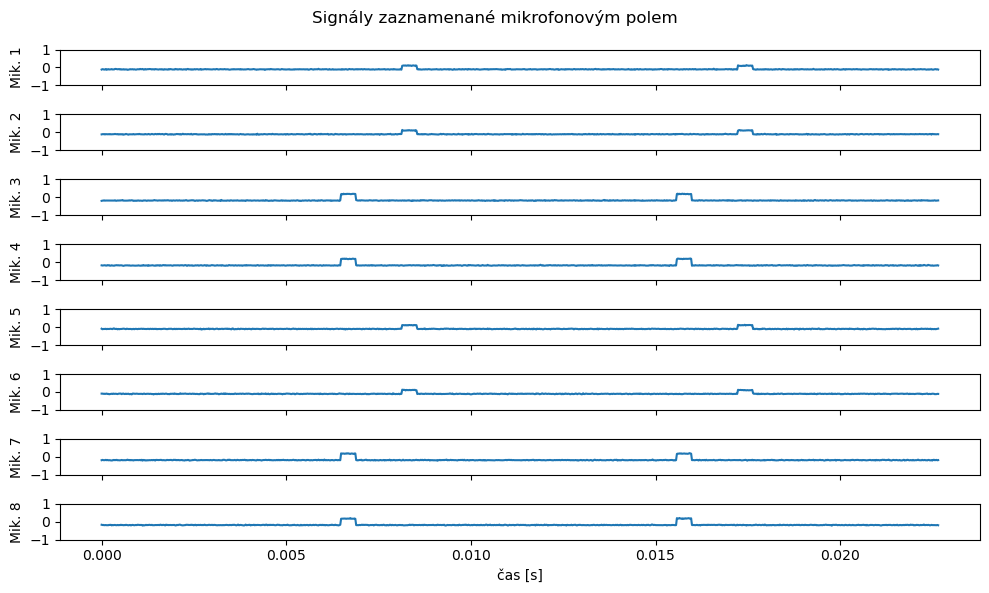

In [12]:
import numpy as np
from matplotlib import pyplot as plt

np.random.seed(123)

mics = np.asarray([
    [[-1, -1, -1]],
    [[-1, -1, +1]],
    [[-1, +1, -1]],
    [[-1, +1, +1]],
    [[+1, -1, -1]],
    [[+1, -1, +1]],
    [[+1, +1, -1]],
    [[+1, +1, +1]],
], dtype=np.float64)  # shape: (n_mics, 1, dim)

n_mics = mics.shape[0]
T = 100  # [s]
f_sample = 44_100  # [Hz]
v_sound = 340  # [m/s]
f_sound = 110  # [Hz]

t = np.arange(0, T, 1 / f_sample)  # shape: (N, )
trajectory = 0.5 * np.asarray([
    np.sin(2 * np.pi * t * 2 / T),
    np.cos(2 * np.pi * t * 2 / T),
    t / T,
], dtype=np.float64).T  # shape: (N, dim)

def generate_sound(t):
    return np.sign(np.sin(2 * np.pi * f_sound * t) - 0.99)

relative_positions = trajectory[None, ...] - mics  # shape: (n_mics, n_samples, dim)
distances = np.linalg.norm(relative_positions, axis=-1)  # shape: (n_mics, n_samples)
delays = distances / v_sound  # shape: (n_mics, n_samples)
gains = 1 / (1 + 2 * distances**2)  # shape: (n_mics, n_samples)
sounds = np.asarray([
    gains[i] * generate_sound(t - delays[i]) + 0.01 * np.random.randn(len(t))
    for i in range(n_mics)
], dtype=np.float64)  # shape: (n_mics, n_samples)

# Plot first 1000 samples for each channel
fig, axs = plt.subplots(n_mics, 1, figsize=(10, 6), sharex=True)
for i_mic in range(n_mics):
    axs[i_mic].plot(t[:1000], sounds[i_mic, :1_000])
    axs[i_mic].set_ylabel(f'Mik. {i_mic + 1}')
    axs[i_mic].set_ylim(-1.0, 1.0)
axs[-1].set_xlabel("čas [s]")
fig.suptitle("Signály zaznamenané mikrofonovým polem")
plt.tight_layout()
plt.show()

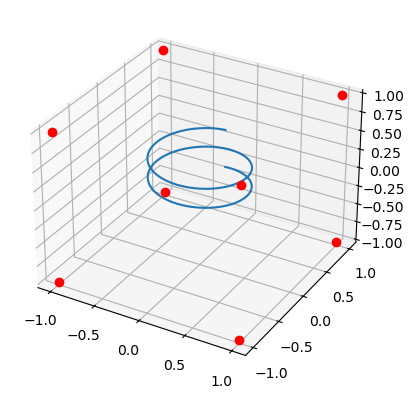

In [13]:
from matplotlib import pyplot as plt

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.plot(trajectory[:, 0], trajectory[:, 1], trajectory[:, 2])
for i_mic in range(n_mics):
    ax.plot(mics[i_mic, 0, 0], mics[i_mic, 0, 1], mics[i_mic, 0, 2], 'o', color="red")
plt.show()


## 1. úkol

Rozdělte pro každý mikrofon signál na kratší segmenty. Délku i posun si zvolte sami tak, aby to dovolovalo splnit následující úkoly.

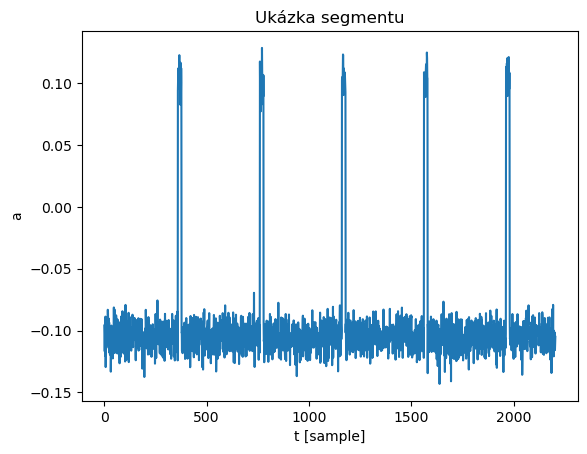

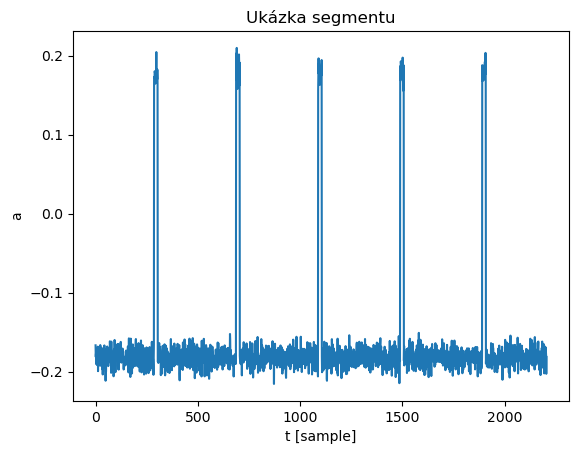

In [14]:
def do_segmentation(x, window_length, stride):
    n_mics, n_T = x.shape
    result = []
    for i_T in range(0, n_T - window_length + 1, stride):
        result.append(x[:, None, i_T:i_T + window_length])
    return np.concatenate(result, axis=1)


window = ...
stride = ...

milliseconds = 0.05
window= int(milliseconds * f_sample)  # [sample]
stride = int(milliseconds * f_sample)  # [sample]

sounds_segmented = do_segmentation(sounds, window, stride)  # shape: (n_mics, n_segments, window)

plt.plot(sounds_segmented[0, 0, :])
plt.xlabel('t [sample]')
plt.ylabel('a')
plt.title('Ukázka segmentu')
plt.show()
plt.plot(sounds_segmented[-1, 0, :])
plt.xlabel('t [sample]')
plt.ylabel('a')
plt.title('Ukázka segmentu')
plt.show()

## 2. úkol

Pro každou dvojici mikrofonů a pro každý segment odhadněte časový posun. Pro dvojice, ve kterých se jedná o ten samý mikrofon, odhadovat zpoždění nemusíte. Můžete bez odhadu použít hodnotu nula sekund.

Pozor: frekvence zvuku ```f_sound``` a vzorkovací frekvence ```f_sample``` určuje, o kolik vzorků maximálně jsme schopni odhadnout zpoždění. Použijte tuto úvahu a zakažte algoritmu odhadovat větší zpoždění než maximálně možné.


In [20]:
def estimate_delta_t_raw(x_a, x_b, f_sample, max_sample):
    X_a = np.fft.fft(x_a)
    X_b = np.fft.fft(x_b)
    C = X_a * X_b.conj()
    c = np.fft.ifft(C).real
    c = c[:max_sample]
    i_sample = np.argmax(c)
    delta_t = i_sample / f_sample
    return delta_t

max_sample = int(f_sample / f_sound)

def apply_estimation(sounds_mics_segmented, estimation, max_sample):
    n_mics, n_segments, segment_length = sounds_mics_segmented.shape

    d_t_estimated = np.zeros((n_mics, n_mics, n_segments), dtype=np.float64)
    for i_segment in range(sounds_mics_segmented.shape[1]):
        for i1_mic in range(n_mics):
            for i2_mic in range(n_mics):
                if i1_mic == i2_mic:
                    continue
                d_t_estimated[i1_mic, i2_mic, i_segment] = estimation(
                    sounds_mics_segmented[i1_mic, i_segment],
                    sounds_mics_segmented[i2_mic, i_segment],
                    f_sample,
                    max_sample
                )
    return d_t_estimated


def estimate_delta_t_enhanced(x_a, x_b, f_sample, max_sample):

    t_ab = estimate_delta_t_raw(x_a, x_b, f_sample, max_sample)
    t_ba = estimate_delta_t_raw(x_b, x_a, f_sample, max_sample)

    if t_ab > t_ba:
        return -t_ba
    return t_ab


delays_differences_estimation = apply_estimation( # časová esimace
      sounds_segmented,
    #   estimate_delta_t_raw,
      estimate_delta_t_enhanced,
      max_sample
)

# delays_differences_estimation = ...  # shape: (n_mics, n_mics, n_segments)

Ověřte, že správně odhadujete rozdíly i pro záporné hodnoty.

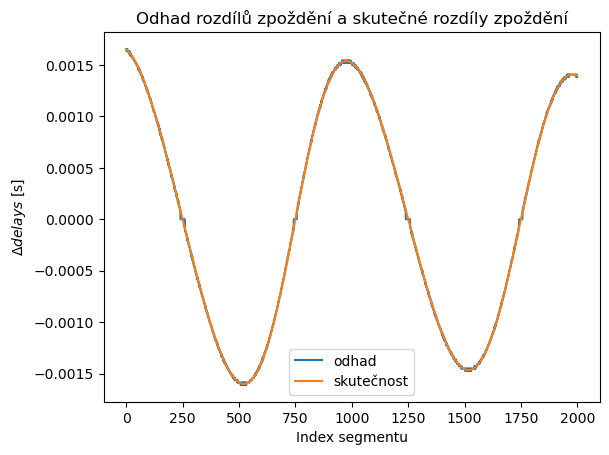

In [21]:
real_delays_difference_0_2 = delays[0, ::stride] - delays[2, ::stride]

plt.plot(delays_differences_estimation[0, 2, :], label="odhad")
plt.plot(real_delays_difference_0_2, label="skutečnost")
plt.xlabel("Index segmentu")
plt.ylabel(r'$\Delta delays$ [s]')
plt.title('Odhad rozdílů zpoždění a skutečné rozdíly zpoždění')
plt.legend()
plt.show()


## 3. úkol

Použijte rychlost zvuku a přepočtěte rozdíly časů na rozdíly poloh. Z rozdílu poloh a pomocí známých poloh mikrofonů v mikrofonovém poli odhadněte absolutní polohu objektu v čase. Stačí jedna poloha pro každý segment. Využijte nějakou metodu hledající přibližné řešení.

In [25]:
from scipy.optimize import least_squares

In [26]:
relative_positions_differences_estimation = delays_differences_estimation * v_sound

def matrix2coordinates(matrix, mics):
    """
    Parameters
    ----------
    matrix : (n_mics, n_mics) array
        matrix[i, j] = distance(x, mics[i]) - distance(x, mics[j])
    mics : (n_mics, dim) array
        Microphone coordinates.

    Returns
    -------
    coordinates : (dim,) array
        Estimated source coordinates.
    """
    matrix = np.asarray(matrix, dtype=float)
    mics = np.asarray(mics, dtype=float)

    n_mics, dim = mics.shape

    # Use only one triangle to avoid redundant equations.
    i, j = np.triu_indices(n_mics, k=1)
    observed = matrix[i, j]

    def residuals(x):
        distances = np.linalg.norm(x - mics, axis=1)
        predicted = distances[i] - distances[j]
        return predicted - observed

    # Initialize at the centroid of the microphones.
    x0 = mics.mean(axis=0)

    result = least_squares(residuals, x0)

    return result.x


Vykreslete nalezené řešení.

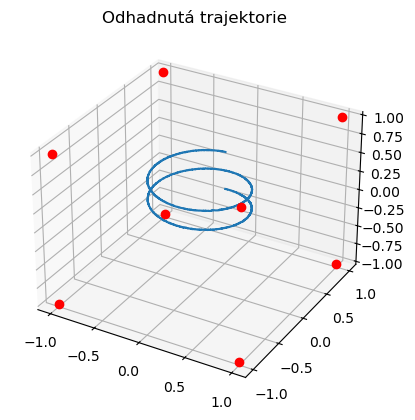

In [27]:
mics3d = mics[:, 0, :]
trajectory_estimated = []
for i_frame in range(relative_positions_differences_estimation.shape[2]):
    trajectory_estimated.append(
          matrix2coordinates(relative_positions_differences_estimation[:, :, i_frame], mics3d)
    )
trajectory_estimated = np.asarray(trajectory_estimated, dtype=np.float64)
mics_estimated = mics

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.plot(trajectory_estimated[:, 0], trajectory_estimated[:, 1], trajectory_estimated[:, 2])
for i_mic in range(n_mics):
    ax.plot(mics_estimated[i_mic, 0, 0], mics_estimated[i_mic, 0, 1], mics_estimated[i_mic, 0, 2], 'o', color="red")
plt.title('Odhadnutá trajektorie')
plt.show()

Porovnejte se skutečnou trajektorií.

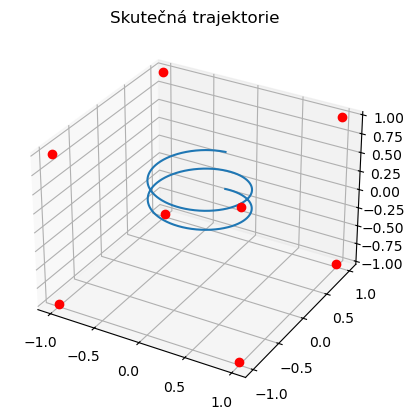

In [28]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.plot(trajectory[:, 0], trajectory[:, 1], trajectory[:, 2])
for i_mic in range(n_mics):
    ax.plot(mics[i_mic, 0, 0], mics[i_mic, 0, 1], mics[i_mic, 0, 2], 'o', color="red")
plt.title('Skutečná trajektorie')
plt.show()

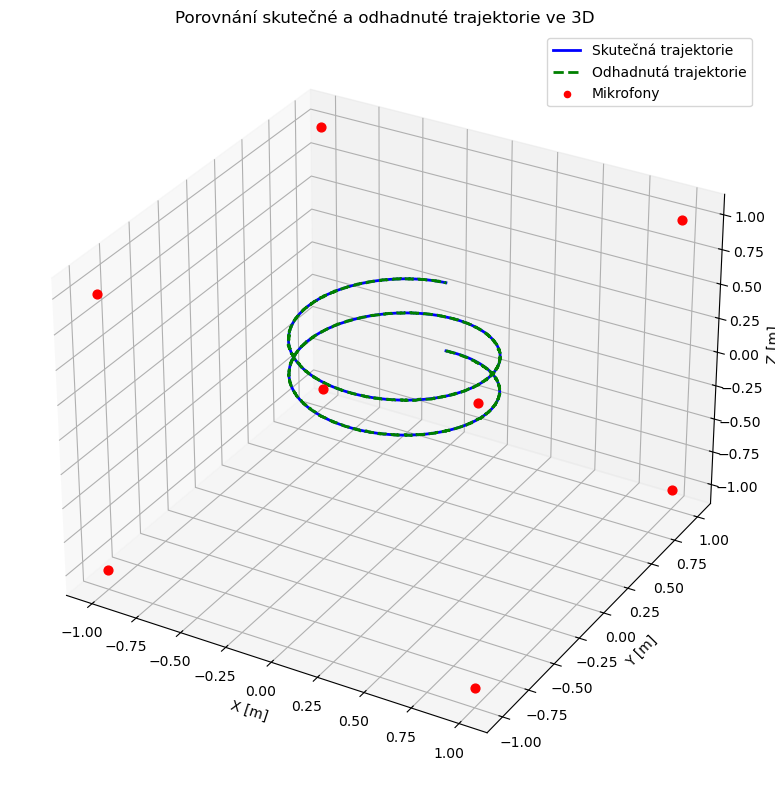

In [ ]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection='3d')

# 1. Skutečná trajektorie
ax.plot(
    trajectory[::stride, 0], 
    trajectory[::stride, 1], 
    trajectory[::stride, 2], 
    label='Skutečná trajektorie', 
    color='blue', 
    linewidth=2
)

# 2. Odhadnutá trajektorie z TDoA
ax.plot(
    trajectory_estimated[:, 0], 
    trajectory_estimated[:, 1], 
    trajectory_estimated[:, 2], 
    label='Odhadnutá trajektorie', 
    color='black', 
    linestyle=':', 
    linewidth=2
)

# 3. Mikrofony
for i_mic in range(n_mics):
    ax.scatter(
        mics[i_mic, 0, 0], 
        mics[i_mic, 0, 1], 
        mics[i_mic, 0, 2], 
        color='red', 
        s=40
    )
# Samostatný scatter jen pro položku v legendě
ax.scatter([], [], [], color='red', label='Mikrofony')

ax.set_xlabel('X [m]')
ax.set_ylabel('Y [m]')
ax.set_zlabel('Z [m]')
ax.set_title('Porovnání skutečné a odhadnuté trajektorie ve 3D')
ax.legend()
plt.tight_layout()
plt.show()

## 4. úkol

Považujte polohy mikrofonů za neměnné, avšak neznámé. Odhadněte najednou nejen trajektorii, ale i polohy mikrofonů. Vykreslete nalezené řešení.

Výsledné řešení nemusí odpovídat původním souřadnicím. Za správné považujte i řešení, které se od skutečného řešení liší posunutím, otočením nebo zrcadlením souřadnicového systému.

In [ ]:
...

## Dobrovolné úkoly nad rámec zadání

...

## Závěr

...